# Part 3: Machine Learning Basics

**Author:** Enock Niyonkuru · **Questions?** Email [enock.niyonkuru@ucsf.edu](mailto:enock.niyonkuru@ucsf.edu)

**Goal:** understand the vocabulary (AI, ML, LLM, foundation model, fine-tuning...) and train a few small models yourself, so that our project, **fine-tuning a foundation model on single-cell data**, makes sense to you.

| Notebook | What you learn |
|---|---|
| 1. Python basics | The language itself |
| 2. Data science | Load, explore and plot tables |
| **3. Machine learning (this one)** | **ML concepts, GitHub / Hugging Face, training and fine-tuning small models** |

You won't write much new code here. Mostly you will **run cells, read the output, and change a few numbers** to see what happens.

## The project in plain words
- **Single-cell data:** a big table where each row is a cell and each column is a gene. The numbers say how active each gene is in that cell.
- **Foundation model** (for example Geneformer or scGPT): a very large model **pre-trained** on millions of cells, so it already knows general patterns of how genes behave.
- **Fine-tuning:** training that model a little more on **your own, smaller dataset** so it gets good at your question (for example, recognising cell types in your tissue).

## What we'll cover
| Section | Question it answers |
|---|---|
| 1. Concepts | What do all these buzzwords mean, and how do they connect? |
| 2. GitHub and Hugging Face | Where do code and pre-trained models live? |
| 3. Supervised learning | How does a model learn from labelled examples, and how do I check it honestly? |
| 4. Unsupervised learning | How do I find structure when there are no labels? |
| 5. Semi-supervised learning | What if only a few cells have labels? |
| 6. Fine-tuning | Why does starting from a pre-trained model help? |

## Datasets
Two small datasets that come built into `scikit-learn`, so there is nothing to download:
- **Breast tumour measurements** (Section 3): 569 samples, 30 numbers each, labelled malignant or benign. A table, just like Part 2.
- **Handwritten digits** (Sections 4 to 6): 1,797 tiny 8x8 images. Each image is a row of 64 numbers with a known label, so it works as a **stand-in for a cell** (a row of gene numbers with a known cell type).

> **An honest note:** these are stand-ins, not single-cell data. Real single-cell data is bigger and noisier, and real foundation models are far larger. The *ideas* carry over directly, and that is what matters here.

## Before you start
- Run cells **from top to bottom**. Most finish in seconds on a laptop or free Colab CPU.
- Technical warnings are hidden to keep the output clean. (Normally you'd see notes like "did not converge". They're hints, not failures.)
- The optional cell in Section 2 downloads a small model and needs internet. It skips politely if that isn't available.

## Contents
1. Concepts: how all the buzzwords connect
2. Important tools: GitHub and Hugging Face
3. Supervised learning
4. Unsupervised learning
5. Semi-supervised learning
6. Fine-tuning a simple model

Run the cell below first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")    # hide technical warnings to keep the output clean

# 1. Understanding the Concepts

**In plain English:** These terms are nested, like Russian dolls.
**AI** is the broad goal of making computers do "smart" things. **Machine learning (ML)** is the part of AI where computers *learn patterns from examples* instead of following hand-written rules. **Deep learning** is ML with large neural networks. A **foundation model** is a huge deep-learning model **pre-trained** on broad data so it can be adapted to many tasks. **LLMs** (like ChatGPT or Claude) are foundation models for text, and **Geneformer** and **scGPT** are foundation models for single cells. **Fine-tuning** adapts a pre-trained model to your own task using your own, smaller dataset.

**Lab analogy:** Think of training a new lab member.
- *Supervised:* a senior tech labels slides "normal" or "abnormal" until you can do it.
- *Unsupervised:* you sort unlabelled slides into piles that look alike.
- *Semi-supervised:* you get a few labelled slides and a big unlabelled pile.
- *Reinforcement:* you try protocols and learn from what succeeds.
- *Foundation model + fine-tuning:* a graduate with general biology training (pre-trained) joins your lab, and you spend two weeks teaching them your specific assay (fine-tuning) instead of training them from the very beginning.

**Watch out for**
- The terms are nested, not interchangeable. "AI" is not the same as "LLM".
- You don't always need a huge model. A simple one is often good enough (you'll see this in Section 3).
- "Pre-trained" doesn't mean "no need to check". Always test on your own data.

| Term | Plain-English meaning |
|---|---|
| **AI** | Any computer system doing something that normally needs human intelligence. The biggest umbrella. |
| **ML** | AI that **learns patterns from examples** instead of hand-written rules. |
| **Deep learning** | ML using large *neural networks* (many layers). Powers images, speech, language, proteins. |
| **LLM** | A deep-learning model trained on huge amounts of text to predict the next word (ChatGPT, Claude). |
| **Foundation model** | A **big model pre-trained on huge, broad data** that can be adapted to many tasks (scGPT, Geneformer). |
| **Pre-training** | The expensive first stage: learn general patterns from lots of data. |
| **Fine-tuning** | The cheap second stage: **keep training** a pre-trained model on *your* small dataset for *your* task. |
| **Supervised** | Learn from **labelled** examples. *Cell expression to cell type.* |
| **Unsupervised** | **No labels**, find structure on your own. *Grouping cells into clusters.* |
| **Semi-supervised** | **A few labels plus lots of unlabelled** data. *Label 5% of cells, let the model label the rest.* |
| **Reinforcement learning** | Learn by **trial and reward**. *A model improves because humans score its answers.* |

## Let's run it
Three pictures to fix the ideas in your mind. **You don't need to understand the code that draws them.** Just run each cell and look.

**Picture 1: how the big terms nest.** AI contains ML, which contains deep learning, which contains foundation models (LLMs and single-cell models live in the middle).

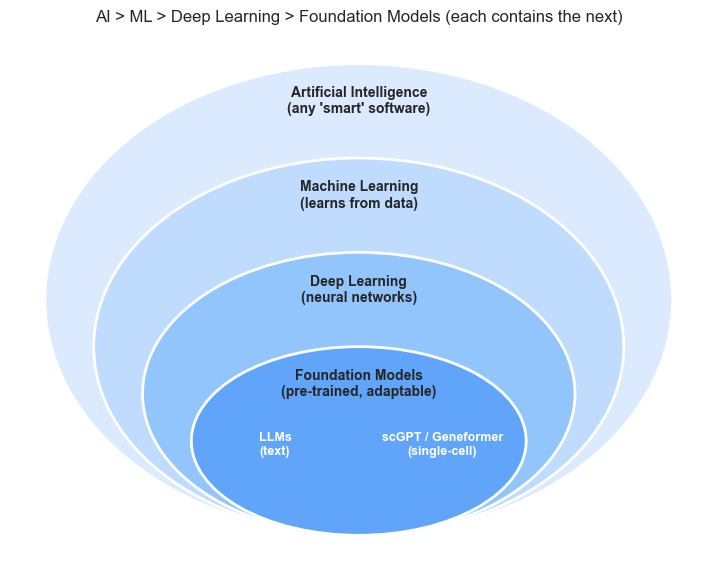

In [2]:
from matplotlib.patches import Ellipse

# (label, width, height, colour), from the biggest oval to the smallest
levels = [
    ("Artificial Intelligence\n(any 'smart' software)", 9.0, 7.0, "#dbeafe"),
    ("Machine Learning\n(learns from data)",            7.6, 5.6, "#bfdbfe"),
    ("Deep Learning\n(neural networks)",                6.2, 4.2, "#93c5fd"),
    ("Foundation Models\n(pre-trained, adaptable)",     4.8, 2.8, "#60a5fa"),
]
bottom = -3.5    # all ovals share the same bottom edge

fig, ax = plt.subplots(figsize=(9, 7))
for text, w, h, colour in levels:
    ax.add_patch(Ellipse((0, bottom + h/2), w, h, color=colour, ec="white", lw=2))
for text, w, h, colour in levels:
    ax.text(0, bottom + h - 0.55, text, ha="center", va="center", fontsize=10, weight="bold")

ax.text(-1.2, -2.3, "LLMs\n(text)", ha="center", fontsize=9, color="white", weight="bold")
ax.text( 1.2, -2.3, "scGPT / Geneformer\n(single-cell)", ha="center", fontsize=9, color="white", weight="bold")

ax.set_xlim(-5, 5); ax.set_ylim(-4, 4); ax.axis("off")
ax.set_title("AI > ML > Deep Learning > Foundation Models (each contains the next)")
plt.show()

**Picture 2: the learning styles differ by how many labels you have.** Same 150 made-up points three times: all labels known (supervised), none (unsupervised), or just 9 (semi-supervised).

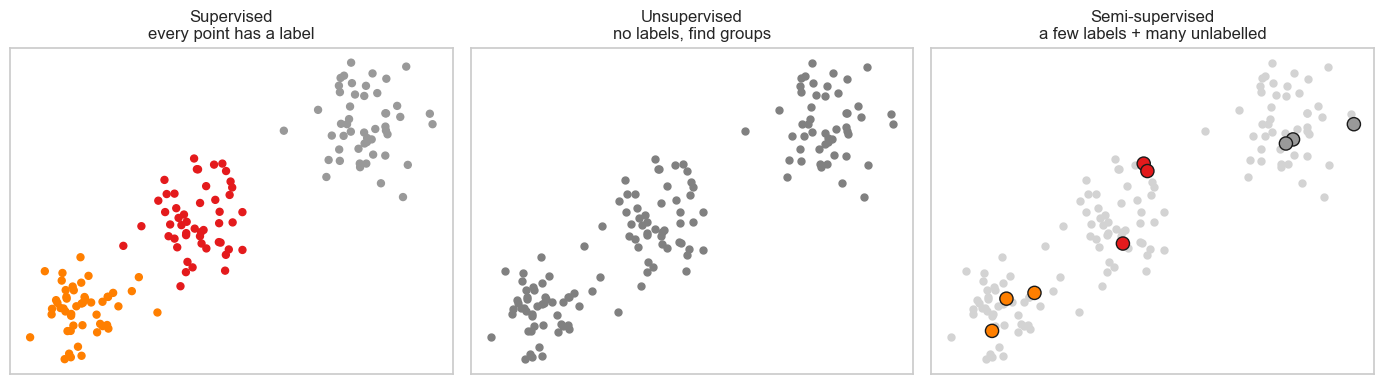

In [3]:
from sklearn.datasets import make_blobs

points, group = make_blobs(n_samples=150, centers=3, cluster_std=1.2, random_state=3)
rng = np.random.default_rng(0)
# pretend only 9 points are labelled: 3 from each group
few = np.concatenate([rng.choice(np.where(group == g)[0], 3, replace=False) for g in range(3)])

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].scatter(points[:, 0], points[:, 1], c=group, cmap="Set1", s=25)
ax[0].set_title("Supervised\nevery point has a label")

ax[1].scatter(points[:, 0], points[:, 1], c="grey", s=25)
ax[1].set_title("Unsupervised\nno labels, find groups")

ax[2].scatter(points[:, 0], points[:, 1], c="lightgrey", s=25)
ax[2].scatter(points[few, 0], points[few, 1], c=group[few], cmap="Set1", s=90, edgecolor="k")
ax[2].set_title("Semi-supervised\na few labels + many unlabelled")

for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

**Picture 3: which approach should I use?** Start at the top question and follow the arrows.

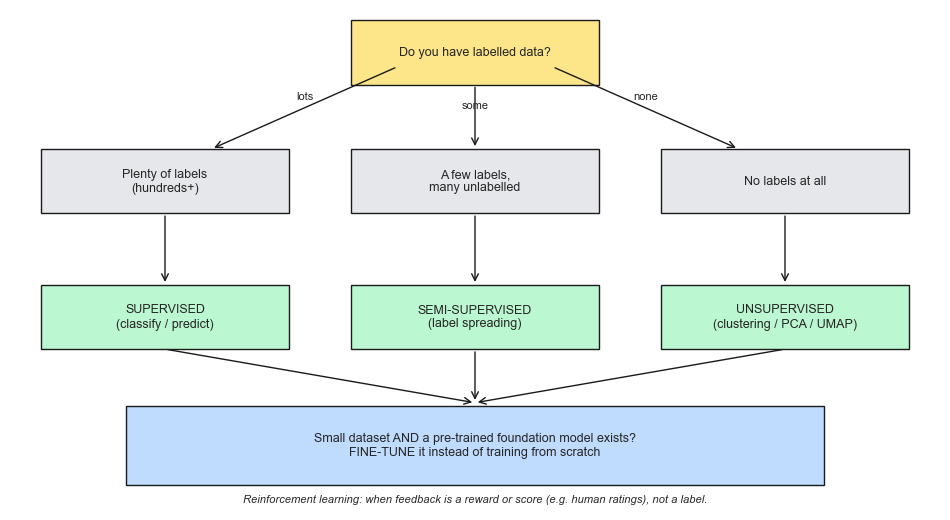

In [4]:
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 7)

def box(x, y, text, colour="#e5e7eb", w=3.2, h=0.9):     # draw a box with text
    ax.add_patch(plt.Rectangle((x - w/2, y - h/2), w, h, fc=colour, ec="k", lw=1, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, zorder=3)

def arrow(x1, y1, x2, y2, text=""):                       # draw an arrow with a label
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="k"))
    ax.text((x1 + x2)/2, (y1 + y2)/2 + 0.12, text, fontsize=8, ha="center")

box(6, 6.4, "Do you have labelled data?", "#fde68a")
box(2, 4.6, "Plenty of labels\n(hundreds+)");   arrow(5, 6.2, 2.6, 5.05, "lots")
box(6, 4.6, "A few labels,\nmany unlabelled"); arrow(6, 5.95, 6, 5.05, "some")
box(10, 4.6, "No labels at all");                arrow(7, 6.2, 9.4, 5.05, "none")

box(2, 2.7, "SUPERVISED\n(classify / predict)", "#bbf7d0");            arrow(2, 4.15, 2, 3.15)
box(6, 2.7, "SEMI-SUPERVISED\n(label spreading)", "#bbf7d0");          arrow(6, 4.15, 6, 3.15)
box(10, 2.7, "UNSUPERVISED\n(clustering / PCA / UMAP)", "#bbf7d0");     arrow(10, 4.15, 10, 3.15)

box(6, 0.9, "Small dataset AND a pre-trained foundation model exists?\nFINE-TUNE it instead of training from scratch", "#bfdbfe", w=9, h=1.1)
for x in (2, 6, 10):
    arrow(x, 2.25, 6, 1.5)

ax.text(6, 0.1, "Reinforcement learning: when feedback is a reward or score (e.g. human ratings), not a label.", ha="center", fontsize=8, style="italic")
plt.show()

## Try it yourself
For each situation, decide: *supervised, unsupervised, semi-supervised, or fine-tuning a foundation model?* Use the flow chart. Type your answers (with a short reason) in the cell below.
1. 50,000 cells, nobody has annotated them, and you want to discover subtypes.
2. 20,000 cells, and an expert labelled 500 of them.
3. 8,000 cells all labelled by cell type, and you want to predict cell type for new cells.
4. 300 labelled cells from a rare disease, and Geneformer is available.

In [5]:
# For each question, ask yourself:
#   - Are there labels? All of them, a few, or none?
#   - Is there a pre-trained model I could start from?
# Then follow the flow chart above.

answers = {
    1: "",   # hint: are any cells labelled? what are you trying to find?
    2: "",   # hint: 500 of 20,000 is only 2.5%
    3: "",   # hint: every cell has a label
    4: "",   # hint: very few labels, but a big pre-trained model exists
}
answers

{1: '', 2: '', 3: '', 4: ''}

# 2. Important Tools: GitHub and Hugging Face

**In plain English:** **Git** records every version of your code so you can go back to any earlier state. **GitHub** is the website where Git projects ("repositories") are stored and shared. **Hugging Face** is "GitHub for machine learning": thousands of pre-trained models and datasets you can download with one line of code.

**Lab analogy:** GitHub is your **shared lab notebook with a full undo history**: you can see who changed which step of the protocol, and when. Hugging Face is the **reagent catalogue**: someone has already made the antibody (the pre-trained model), and you just order it.

**Key terms**
- **Repository (repo):** a project folder whose history is tracked.
- **Commit:** a saved snapshot of your files, with a short message.
- **Model card:** a model's documentation page: what it was trained on, what it's for, and its limits.
- **Weights:** the numbers a model has learned. "Downloading a model" mostly means downloading its weights.

**Watch out for**
- **Never commit passwords, access tokens or patient data.** Once pushed, they are hard to remove.
- Write useful commit messages ("Raise min genes to 500", not "changes").
- **Read the model card.** A model trained on another species or tissue may not work for your data.
- Git is for code, not for gigabytes of data.

## Let's run it

### GitHub essentials
1. Create an account at <https://github.com>.
2. Key words: **clone** = download a copy · **commit** = save a snapshot · **push** = upload your commits · **pull** = download others' updates · **branch** = a parallel version to try things safely · **pull request** = "please review and merge my changes".

Typical workflow (in a terminal):
```bash
git clone https://github.com/<user>/<repo>.git   # get the project
cd <repo>
git checkout -b my-feature                        # make a new branch
# ... edit files ...
git add .                                         # stage your changes
git commit -m "Add QC filtering"                  # save a snapshot
git push origin my-feature                        # upload, then open a Pull Request on GitHub
git pull                                          # later: get teammates' updates
```

### Hugging Face essentials
1. Create an account at <https://huggingface.co>.
2. Browse **Models** (try searching "single cell") and **Datasets**.
3. Open a model's **model card** and read it.
4. For private or "gated" models you need an access token: *Settings → Access Tokens*.
5. Install the tools: `pip install transformers datasets huggingface_hub`

**Optional: try a pre-trained model.** This downloads a small ready-made text model from Hugging Face and asks whether two sentences are positive or negative. You should see `POSITIVE` and `NEGATIVE` with confidence scores near 1. Without internet it prints "Skipped" and you can carry on.

In [6]:
try:
    from transformers import pipeline
    clf = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
    print(clf(["This experiment worked beautifully!", "The cells all died overnight."]))
except Exception as e:
    print("Skipped (no transformers/internet):", type(e).__name__)

Device set to use mps:0


[{'label': 'POSITIVE', 'score': 0.9998588562011719}, {'label': 'NEGATIVE', 'score': 0.9994258880615234}]


That one `pipeline(...)` line downloaded a **pre-trained model from Hugging Face** and used it. In our project we'll do the same with a single-cell foundation model, and then fine-tune it.

## Try it yourself
1. Create GitHub and Hugging Face accounts if you haven't.
2. On Hugging Face, search for **"Geneformer"** or **"scGPT"** and open the model card (or GitHub page). Write your findings as comments below.

In [ ]:
# Where to look: on the model page, read the "Model card" tab (or the README on GitHub).
# Search the page (Ctrl+F / Cmd+F) for words like "pretrain", "corpus", "million" or "dataset".

# Model:
# Trained on (what data? which species/tissues?):
# Number of cells:
# What tasks is it meant for?:

# 3. Supervised Learning

**In plain English:** You give the computer **inputs (features)** together with the **correct answers (labels)**. It learns the rule linking them, then predicts labels for new examples. If the answer is a category (malignant or benign), it's **classification**. If it's a number (drug response), it's **regression**. The golden rule: **hold back a test set** the model never sees while learning.

**Lab analogy:** Studying with flashcards. You learn from the flashcards (the **training set**), then sit an exam with questions you haven't seen (the **test set**). The exam score, not the flashcard score, shows what you really learned.

**Key terms**
- **Feature:** one input measurement (in single-cell data, one gene).
- **Label:** the correct answer (in single-cell data, the cell type).
- **Training / test set:** what the model learns from / what it's checked on afterwards.
- **Accuracy:** the fraction of predictions that are correct.
- **Confusion matrix:** a table of true vs predicted labels, showing *which* mistakes were made.
- **Baseline:** a simple model your fancier model has to beat.

**Watch out for**
- **Testing on training data.** That's marking an exam you already studied.
- **Data leakage:** information from the test set sneaking into training (for example, scaling the data *before* splitting).
- **Trusting accuracy alone.** About 63% of our samples are benign, so "always say benign" already scores 63%. Check the confusion matrix too.
- **Skipping the baseline.** Without one you can't tell if a complicated model adds anything.

## Let's run it
**Example:** predict whether a tumour is *malignant* or *benign* from 30 measurements. It's the same idea as predicting cell type from gene expression.

**Load the data.** `X` holds the measurements (features) and `y` the answers (labels). You'll see 569 samples with 30 features, 357 benign and 212 malignant, then the first 5 rows.

In [8]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X = data.data        # features: a table of numbers
y = data.target      # labels: 0 = malignant, 1 = benign

print(X.shape)
print(data.target_names, y.value_counts().to_dict())
X.head()

(569, 30)
['malignant' 'benign'] {1: 357, 0: 212}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Step 1: split into train and test.** Set aside 20% for testing. "Stratified" keeps the same malignant/benign mix in both parts. You'll see `455 train / 114 test`.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(len(X_train), "train /", len(X_test), "test")

455 train / 114 test


**Step 2: train a model** (`.fit` means "learn"). A random forest is a crowd of decision trees that vote. Training prints only a short description of the model.

In [10]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


**Step 3: predict and evaluate** (`.predict`). You'll get the accuracy (about 0.96), a report with **precision** (when it says malignant, how often is it right?) and **recall** (of all truly malignant samples, how many did it find?), and a **confusion matrix**. Correct predictions are on the diagonal, and mistakes are off it.

Accuracy: 0.956
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



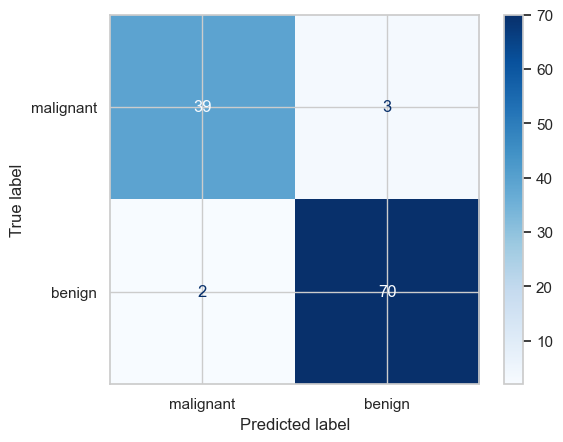

In [11]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=data.target_names))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=data.target_names, cmap="Blues")
plt.show()

**Step 4: which features mattered?** The 10 measurements the forest relied on most. This gives biological hints, but it shows what the model *used*, not what *causes* the difference.

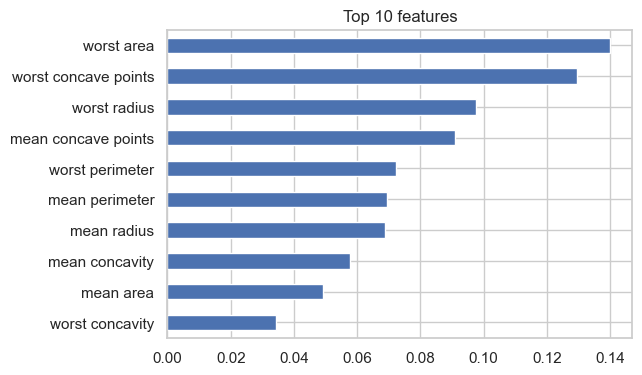

In [12]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

importance.plot.barh(figsize=(6, 4)).invert_yaxis()
plt.title("Top 10 features")
plt.show()

**Compare with a simpler baseline.** Logistic regression is a much simpler model. You'll likely see it do about as well, or even better (around 0.98 vs 0.96), so a fancier model isn't automatically a better one. That's why we always compare. (With only 114 test samples, small differences can flip with a different split.)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# make_pipeline chains "rescale the features" then "logistic regression"
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)

print("Logistic regression accuracy:", round(lr.score(X_test, y_test), 3))
print("Random forest accuracy:      ", round(model.score(X_test, y_test), 3))

Logistic regression accuracy: 0.982
Random forest accuracy:       0.956


## Try it yourself
Change **one thing at a time** and re-run from that cell.
1. Change `n_estimators` to 5, then 300. Does the test accuracy change?
2. Change `test_size` to 0.5 (less training data). What happens?
3. Try `from sklearn.neighbors import KNeighborsClassifier` and compare.
4. Think: why can accuracy be misleading for a rare disease?

In [ ]:
# Change ONE thing at a time, then compare with the scores above.

# Idea 1: more or fewer trees -> copy the RandomForest cell and change n_estimators
# small_forest = RandomForestClassifier(n_estimators=5, random_state=42).fit(X_train, y_train)
# print("5 trees:", small_forest.score(X_test, y_test))

# Idea 2: less training data -> scroll up, change test_size=0.2 to 0.5, re-run from there

# Idea 3: a different model. Same pattern every time: create -> .fit() -> .score()
# from sklearn.neighbors import KNeighborsClassifier
# knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
# print("KNN:", knn.score(X_test, y_test))

# Idea 4 (thinking, no code): if only 1 in 100 patients has the disease,
# what accuracy would "always say healthy" get?

# 4. Unsupervised Learning

**In plain English:** There are **no labels**, so the algorithm looks for structure on its own. Two common jobs: **clustering** (group similar items, e.g. K-means) and **dimensionality reduction** (squeeze many columns down to 2 or 3 so you can plot them, e.g. PCA or UMAP).

**Lab analogy:** You get a box of **unlabelled photos of strangers** and sort them into piles by hair, age and clothes, without knowing anyone's name. Later someone tells you who the groups are. This is the backbone of single-cell analysis: 20,000 genes per cell become a 2D map, and cells are clustered into proposed populations.

**Key terms**
- **Dimension:** one column of your data. A cell with 20,000 genes has 20,000 dimensions.
- **PCA:** finds the directions along which your data varies most, so each item can be described with 2 or 3 numbers instead of thousands.
- **Cluster:** a group of items more similar to each other than to the rest.
- **K-means:** a clustering method where you choose the number of groups, `k`.
- **Inertia:** how spread out items are around their cluster centres (smaller = tighter).

**Watch out for**
- K-means always returns exactly `k` clusters, **whether or not they are real**.
- Clusters are a proposal, not proven cell types. Check them (e.g. with marker genes).
- A 2D map distorts distances. Use it to look and get ideas, not as proof.

## Let's run it
**Example:** handwritten digits (8x8 pixel images, so 64 numbers each). We *pretend we have no labels*, cluster, and then check.

**Load the digits** and show the first 8. You'll see `(1797, 64)` and a row of small digit pictures. The titles are the true digits, but the clustering below won't use them.

(1797, 64)


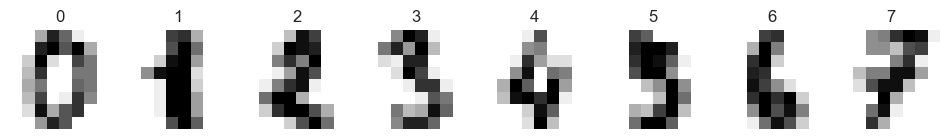

In [15]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits, y_digits = digits.data, digits.target      # 64 pixel numbers per image, and the true digit
print(X_digits.shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    a.imshow(digits.images[i], cmap="gray_r")
    a.set_title(y_digits[i])
    a.axis("off")
plt.show()

**Step 1: PCA.** Squash the 64 numbers per image into 2, so each image becomes one dot. The printed numbers say how much of the total variation each new axis keeps (about 0.15 and 0.14, so only ~29% together: two numbers keep just part of the story).

variance explained: [0.149 0.136]


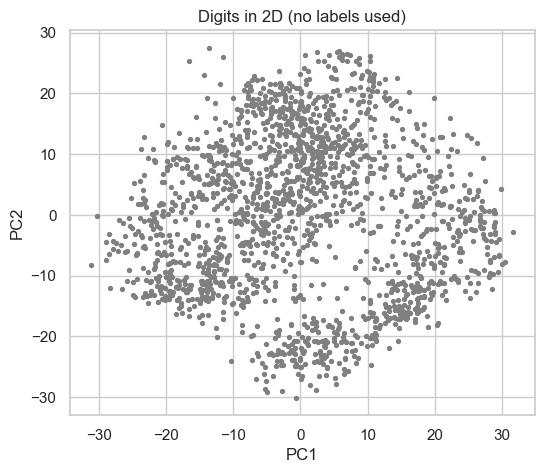

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
Z = pca.fit_transform(X_digits)
print("variance explained:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(6, 5))
plt.scatter(Z[:, 0], Z[:, 1], s=8, c="grey")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Digits in 2D (no labels used)")
plt.show()

**Step 2: K-means.** Ask for 10 groups, using only the pixel numbers, and colour the same map by group. The colours are just group numbers with no meaning by themselves.

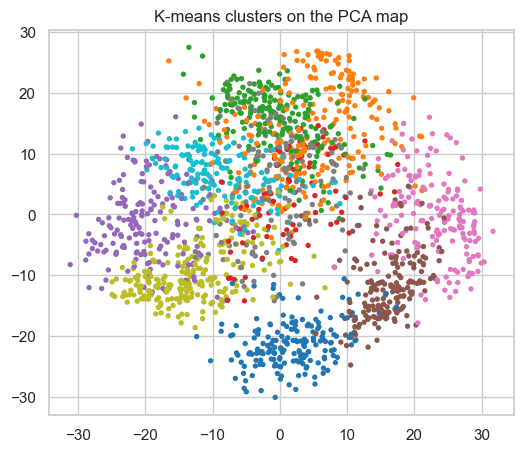

In [17]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=10, n_init=10, random_state=0)
clusters = km.fit_predict(X_digits)

plt.figure(figsize=(6, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=clusters, cmap="tab10", s=8)
plt.title("K-means clusters on the PCA map")
plt.show()

**Step 3: peek at the answer key** (only possible in a teaching example). The **adjusted Rand index** is 1 for perfect agreement and 0 for random (here about 0.67, a partial match). In the table, each row is a cluster and each column a true digit. A good cluster has one big number in its row. Rows with two big numbers show digits that got mixed together.

In [18]:
from sklearn.metrics import adjusted_rand_score

print("Adjusted Rand index (1 = perfect):", round(adjusted_rand_score(y_digits, clusters), 3))
pd.crosstab(clusters, y_digits, rownames=["cluster"], colnames=["true digit"])

Adjusted Rand index (1 = perfect): 0.666


true digit,0,1,2,3,4,5,6,7,8,9
cluster,,,,,,,,,,
0,176,0,1,0,0,0,1,0,0,0
1,0,100,8,7,2,0,3,2,100,1
2,0,0,3,7,11,0,0,174,5,8
3,0,54,2,0,3,0,0,2,6,20
4,0,1,13,154,0,2,0,0,2,6
5,0,2,0,0,0,1,177,0,2,0
6,2,0,0,0,165,2,0,0,0,0
7,0,1,0,2,0,136,0,1,4,6
8,0,0,2,13,0,41,0,0,52,139


**Optional: how do you choose `k`?** Try several values and look for an "elbow" where the curve stops dropping quickly. It's only a hint, and the elbow is often gentle. This takes a few seconds.

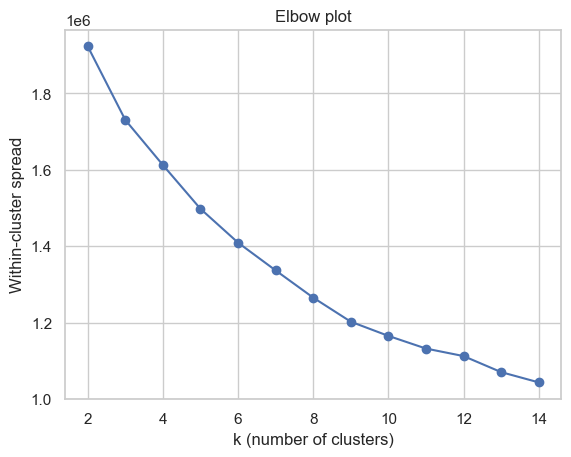

In [19]:
ks = range(2, 15)
inertia = [KMeans(n_clusters=k, n_init=5, random_state=0).fit(X_digits).inertia_ for k in ks]

plt.plot(list(ks), inertia, "o-")
plt.xlabel("k (number of clusters)")
plt.ylabel("Within-cluster spread")
plt.title("Elbow plot")
plt.show()

## Try it yourself
1. Re-run K-means with `n_clusters=5` and plot it on the PCA map. How does it look?
2. Use 3 PCA components and check `explained_variance_ratio_.sum()`. How much do 2 vs 3 vs 10 components keep?
3. Which two digits get mixed together most often in the table above?

In [ ]:
# Task 1: 5 clusters instead of 10 -> copy the K-means cell and change n_clusters
# km5 = KMeans(n_clusters=5, n_init=10, random_state=0)
# clusters5 = km5.fit_predict(X_digits)
# plt.scatter(Z[:, 0], Z[:, 1], c=clusters5, cmap="tab10", s=8)
# plt.show()

# Task 2: how much information do more PCA components keep?
# for n in [2, 3, 10]:
#     p = PCA(n_components=n).fit(X_digits)
#     print(n, "components keep", round(p.explained_variance_ratio_.sum(), 2))

# Task 3 (no code): scroll up to the crosstab table and look for a row
# with two large numbers. Those two digits got mixed together.

# 5. Semi-Supervised Learning

**In plain English:** Labels are expensive (an expert has to annotate cells), but unlabelled data is cheap. **Semi-supervised learning** uses your few labels *and* the structure of all the unlabelled data. In **label spreading**, labels "flow" from labelled points to their nearest unlabelled neighbours.

**Lab analogy:** A teacher grades **10 of 1,000** essays. Most of the others look very similar to one of those 10, so they get the same grade. The few labels are anchors for everything else. This is the realistic situation in many labs: thousands of cells but only a few annotated.

**Key terms**
- **Labelled / unlabelled:** we know / don't know the correct answer.
- **Label spreading:** passing known labels to the most similar unlabelled examples.
- **Nearest neighbours:** the most similar examples. `n_neighbors` says how many each one listens to.

**Watch out for**
- Keep the **test set out** of training. Test data is only for scoring.
- Compare **fairly**: against a supervised model that gets the *same few labels*, not all of them.
- If your few labels miss some classes, those classes can't be labelled correctly.
- It doesn't always help. If groups overlap or labels are wrong, errors spread too.

## Let's run it
**Example:** hide 95% of the digit labels and see if the model can recover them.

**Hide the labels.** Split the digits into train (70%) and test (30%), then replace 95% of the training labels with `-1`, which scikit-learn reads as "unlabelled". You'll see `Labelled: 61 | Unlabelled: 1196`.

In [21]:
from sklearn.semi_supervised import LabelSpreading
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_digits, y_digits, test_size=0.3, random_state=0, stratify=y_digits)

rng = np.random.default_rng(0)
y_partial = yd_train.copy()
hidden = rng.random(len(yd_train)) > 0.05     # True for ~95% of images
y_partial[hidden] = -1                        # -1 means "unlabelled"

print("Labelled:", (y_partial != -1).sum(), "| Unlabelled:", (y_partial == -1).sum())

Labelled: 61 | Unlabelled: 1196


**Train the semi-supervised model.** It sees all training images, but only the few known labels. Each image looks at its 7 most similar images (`n_neighbors=7`).

In [22]:
semi = LabelSpreading(kernel="knn", n_neighbors=7).fit(Xd_train, y_partial)
print("Semi-supervised test accuracy:", round(semi.score(Xd_test, yd_test), 3))

Semi-supervised test accuracy: 0.931


**A fair comparison.** Train an ordinary supervised model on *only* the few labelled images. You'll see about 0.93 for semi-supervised vs about 0.85 for supervised, so using the unlabelled images helped.

In [23]:
has_label = y_partial != -1
sup = LogisticRegression(max_iter=2000).fit(Xd_train[has_label], y_partial[has_label])

print("Supervised, same few labels:", round(sup.score(Xd_test, yd_test), 3))
print("Semi-supervised:            ", round(semi.score(Xd_test, yd_test), 3))

Supervised, same few labels: 0.852
Semi-supervised:             0.931


**Optional: how does it change with the number of labels?** Repeat the comparison keeping 1%, 2%, 5%, 10% and 30% of the labels. Expect two rising lines. It trains several models, so it takes a little longer.

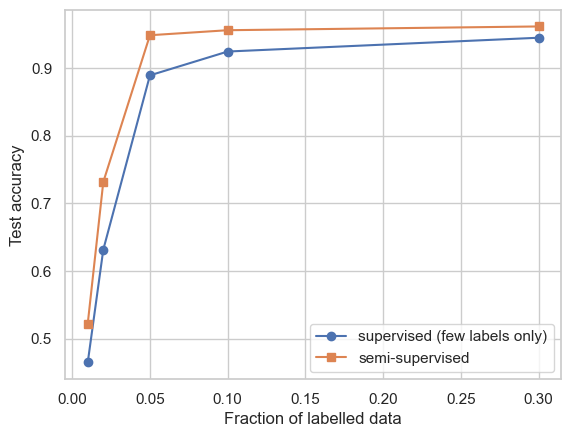

In [24]:
fractions = [0.01, 0.02, 0.05, 0.1, 0.3]
sup_acc, semi_acc = [], []

for f in fractions:
    yp = yd_train.copy()
    yp[np.random.default_rng(1).random(len(yd_train)) > f] = -1     # hide the rest
    has_label = yp != -1
    semi_acc.append(LabelSpreading(kernel="knn", n_neighbors=7).fit(Xd_train, yp).score(Xd_test, yd_test))
    sup_acc.append(LogisticRegression(max_iter=2000).fit(Xd_train[has_label], yp[has_label]).score(Xd_test, yd_test))

plt.plot(fractions, sup_acc, "o-", label="supervised (few labels only)")
plt.plot(fractions, semi_acc, "s-", label="semi-supervised")
plt.xlabel("Fraction of labelled data")
plt.ylabel("Test accuracy")
plt.legend()
plt.show()

## Try it yourself
1. Change `n_neighbors` (try 3 and 15). Does accuracy move?
2. What's the smallest label fraction at which semi-supervised still works well?
3. Think: for single-cell data, where might you get "a few labels"? (**Hint:** marker genes.)

In [ ]:
# Task 1: change n_neighbors -> copy the LabelSpreading line and try 3 and 15
# for k in [3, 7, 15]:
#     model_k = LabelSpreading(kernel="knn", n_neighbors=k).fit(Xd_train, y_partial)
#     print(k, "neighbours:", round(model_k.score(Xd_test, yd_test), 3))

# Task 2: look at the line chart above (if you ran the optional cell).
# Where does the semi-supervised line start to flatten out?

# Task 3 (no code, just think): in single-cell data, which cells could you label
# confidently? Hint: cells with very high expression of a known marker gene,
# like CD3E for T cells.

# 6. Fine-Tuning a Simple Model

**In plain English:** **Fine-tuning** means starting from a model that is already **pre-trained** on a large task, then continuing to train it on your smaller dataset. It already knows general patterns, so it needs far **less data, time and computing power** than training from zero. The recipe: load a pre-trained model, train briefly with a **small learning rate**, evaluate on held-out data.

**Lab analogy:** A **medical resident** already knows anatomy and physiology (pre-training). On joining a cardiology clinic they don't re-learn biology, they specialise (fine-tuning). Our foundation model has "read" millions of cells, and we teach it *our* task with our own few thousand.

**Key terms**
- **Pre-training / fine-tuning:** the big, broad first stage / the short, specific second stage.
- **Learning rate:** the size of each update step. Big steps learn fast but can wreck existing knowledge. Small steps are gentle.
- **Batch effect:** differences between datasets caused by the lab, machine or day rather than the biology.

**Watch out for**
- **Too high a learning rate** can overwrite what the model already knows.
- **Always report two comparisons**: training from scratch, and the pre-trained model with no fine-tuning. Otherwise you can't tell how much fine-tuning helped.
- Keep the test data **completely separate** (e.g. different donors or samples).
- Read the model card. The model must have learned something relevant to your data.

## Let's run it
**Example (runs in seconds):** imagine **Lab A** has a big labelled dataset (our *pre-training* data), and **Lab B** ran the same experiment on a slightly different machine (a *batch effect*: lower contrast and more noise) and only has a **few labelled examples**. We compare:
1. a model trained **from scratch** on Lab B's few examples,
2. the **pre-trained** model from Lab A, used as-is,
3. the pre-trained model **fine-tuned** on Lab B's few examples.

Digits are our stand-in cells again.

**Set up the two labs.** Lab B's images are made fainter and noisier, and Lab B gets only 3 labelled images per digit. You'll see `Lab A (pre-training): 898 | Lab B fine-tune set: 30 | Lab B test set: 869`.

In [26]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

X_all = digits.data / 16.0                     # scale pixels to 0-1
rng = np.random.default_rng(0)

# Lab B = the same digits with lower contrast and extra noise (a "batch effect")
X_noisy = np.clip(X_all * 0.7 + 0.15 * rng.random(X_all.shape), 0, 1)

# Split the images in half: one half is Lab A, the other is Lab B
idx_a, idx_b = train_test_split(np.arange(len(X_all)), test_size=0.5, random_state=0, stratify=y_digits)
X_lab_a, y_lab_a = X_all[idx_a], y_digits[idx_a]
X_lab_b, y_lab_b = X_noisy[idx_b], y_digits[idx_b]

# In Lab B, only N_PER_CLASS labelled images per digit are used for training; the rest is the test set
N_PER_CLASS = 3
train_idx, test_idx = [], []
for digit in range(10):
    positions = np.where(y_lab_b == digit)[0]
    rng.shuffle(positions)
    train_idx += list(positions[:N_PER_CLASS])
    test_idx += list(positions[N_PER_CLASS:])

Xb_train, yb_train = X_lab_b[train_idx], y_lab_b[train_idx]
Xb_test, yb_test = X_lab_b[test_idx], y_lab_b[test_idx]

print("Lab A (pre-training):", len(X_lab_a), "| Lab B fine-tune set:", len(Xb_train), "| Lab B test set:", len(Xb_test))

Lab A (pre-training): 898 | Lab B fine-tune set: 30 | Lab B test set: 869


**1. From scratch.** A small neural network trained on only Lab B's 30 images. Expect about 0.76.

In [27]:
scratch = MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0)
scratch.fit(Xb_train, yb_train)

scratch_acc = scratch.score(Xb_test, yb_test)
print("From scratch:", round(scratch_acc, 3))

From scratch: 0.756


**2. Pre-trained, no fine-tuning.** Train the same network on Lab A's many images (our stand-in for pre-training), then test it directly on Lab B. Expect about 0.95, a big jump.

In [28]:
pre = MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0)
pre.fit(X_lab_a, y_lab_a)

pre_acc = pre.score(Xb_test, yb_test)
print("Pre-trained, no fine-tuning:", round(pre_acc, 3))

Pre-trained, no fine-tuning: 0.946


**3. Fine-tune.** Keep training the *same* model (`warm_start=True` keeps what it learned) on Lab B's 30 images, with a **small learning rate** (`1e-4`) so we nudge it rather than overwrite it. Expect about 0.95, close to step 2, because this toy example is easy.

In [29]:
pre.set_params(warm_start=True, max_iter=100, learning_rate_init=1e-4, tol=1e-9, n_iter_no_change=100)
pre.fit(Xb_train, yb_train)

ft_acc = pre.score(Xb_test, yb_test)
print("Pre-trained + fine-tuned:", round(ft_acc, 3))

Pre-trained + fine-tuned: 0.949


**Compare the three.**

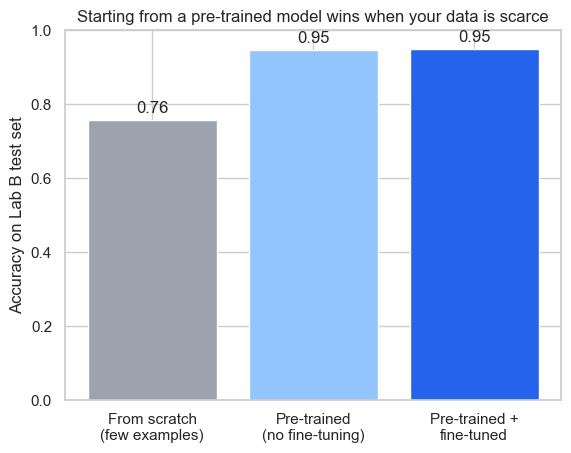

In [30]:
names = ["From scratch\n(few examples)", "Pre-trained\n(no fine-tuning)", "Pre-trained +\nfine-tuned"]
scores = [scratch_acc, pre_acc, ft_acc]

plt.bar(names, scores, color=["#9ca3af", "#93c5fd", "#2563eb"])
plt.ylim(0, 1)
plt.ylabel("Accuracy on Lab B test set")
for i, v in enumerate(scores):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.title("Starting from a pre-trained model wins when your data is scarce")
plt.show()

> **Take-home:** with only 30 labelled examples, the model that started from pre-training beats the one trained from scratch by a lot, because it already "knows" what digits look like. This is why **a foundation model pre-trained on millions of cells can be fine-tuned on a few thousand of yours**, even when your data comes from a different lab or machine.
>
> Here fine-tuning added very little on top of pre-training because the toy task is easy. Don't read much into a difference of 0.003. In real projects, fine-tuning matters more when your data differs more from the pre-training data.

### Preview: fine-tuning a real foundation model (don't run yet)
```python
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

model = AutoModelForSequenceClassification.from_pretrained("<model-name-on-hugging-face>", num_labels=5)
args = TrainingArguments(output_dir="out", learning_rate=2e-5, num_train_epochs=3, per_device_train_batch_size=16)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=test_ds)
trainer.train()
trainer.evaluate()
```
It's the same steps as above: load pre-trained, train a little with a small learning rate, evaluate on held-out data. You'll need a **GPU** (in Colab: *Runtime → Change runtime type → GPU*).

## Try it yourself
1. Change `N_PER_CLASS` to **1**, then **10**, and re-run the setup cell and everything after it. How do the three bars change? When does pre-training matter most?
2. Change the fine-tuning `learning_rate_init` from `1e-4` to `1e-2` and re-run. Does a big learning rate hurt the model's prior knowledge?
3. Reflect: in our single-cell project, what plays the role of the "pre-training data", and what plays "your small dataset"?

In [ ]:
# Task 1: scroll up to the "Set up the two labs" cell.
#   Change N_PER_CLASS = 3 to 1 (then to 10), and re-run that cell AND every cell after it.
#   Write down the three accuracies each time:
#   N_PER_CLASS = 1:  scratch ___  pre-trained ___  fine-tuned ___
#   N_PER_CLASS = 10: scratch ___  pre-trained ___  fine-tuned ___

# Task 2: in the fine-tune cell, change learning_rate_init=1e-4 to 1e-2.
#   Re-run "2. Pre-trained" first (to get a fresh model), then the fine-tune cell.
#   Did the score go up or down?

# Task 3 (no code, just think):
#   "Pre-training data" in our project = ___
#   "Your small dataset" in our project = ___

# You've finished the series!

You started with Python basics, learned to explore data with pandas, and now understand the main ideas behind machine learning and fine-tuning.

| Section | The key idea | Where it shows up in our project |
|---|---|---|
| 1. Concepts | AI > ML > deep learning > foundation models; fine-tuning adapts a pre-trained model | Reading the Geneformer and scGPT papers and model cards |
| 2. GitHub / Hugging Face | Git tracks versions; Hugging Face hosts pre-trained models (read the model card!) | Getting the model and keeping our code safe |
| 3. Supervised | Train on labelled examples, judge on a test set, compare with a baseline | Evaluating a fine-tuned cell-type predictor |
| 4. Unsupervised | PCA and clustering find structure without labels, but `k` and the meaning of clusters need care | First look at a new dataset |
| 5. Semi-supervised | A few labels plus many unlabelled examples can beat the few labels alone | Extending a small set of expert or marker-gene labels |
| 6. Fine-tuning | Start from a pre-trained model and train gently on your small dataset | The core of the project |

Remember: the examples used small stand-in datasets. The ideas carry over, but real single-cell data and real foundation models are bigger and need more care.

## Next steps (you don't need to do everything at once)
1. **Learn scanpy and AnnData**, the standard tools for single-cell data in Python. Follow the PBMC 3k tutorial: <https://scanpy.readthedocs.io>.
2. **Read the model cards** for Geneformer and scGPT. Note what data they were pre-trained on, which species and tissues, the input format, and the licence.
3. **Try a GPU on Colab** and work through the Hugging Face course: <https://huggingface.co/learn>.
4. **Define your project question**: what exactly will the model predict, where do the labels come from, and how many labelled cells do you have? Plan an honest evaluation (keep cells from the same donor out of both train and test).
5. **Keep your work on GitHub**, with clear commit messages, and record the model, dataset and package versions you used.